# Subgrupo A · Regresión logística

Parte de la regresión logística del seminario (apartados 2.2, 2.3 y 4.3 de la wiki). Usa el protocolo común (`common_protocol.py`): misma partición 80/20, misma validación cruzada repetida y mismo criterio de umbral que el resto de modelos.

Guarda en el Drive:
- `results/`: resultados en el formato común, coeficientes, ejemplo a mano, predicciones, equidad y auditoría.
- `graphics/`: gráfica de coeficientes y gráfica de coste según el umbral.

In [1]:
import os, sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import roc_auc_score, brier_score_loss

# Carpeta del seminario (la que tiene common/, results/ y graphics/). En Colab, la ruta del Drive.
FOLDER = "."
sys.path.append(FOLDER)
import common_protocol as cp

r = cp.routes(FOLDER)
SUBGRUPO, MODELO = "A", "logistica"

In [2]:
X_train, X_test, y_train, y_test = cp.load_partition(FOLDER)
num, cat = cp.columns(X_train)
print(f"Entrenamiento: {len(y_train)} casos ({y_train.mean():.1%} impagos)")
print(f"Test: {len(y_test)} casos ({y_test.mean():.1%} impagos)")

Entrenamiento: 800 casos (30.0% impagos)
Test: 200 casos (30.0% impagos)


## 1. Modelo

Mismo esquema que el preprocesado común (todo dentro de un `Pipeline`, ajustado solo con entrenamiento), con un cambio: en el one-hot dejo una **categoría de referencia** por variable. Así cada coeficiente se lee como "frente a la referencia" y los odds ratio tienen una interpretación directa. Las referencias son las categorías de partida (saldo negativo, sin créditos previos, coche nuevo...).

In [3]:
REFERENCIAS = {
    "checking_status": "<0", "credit_history": "no credits/all paid", "purpose": "new car",
    "savings_status": "<100", "employment": "unemployed", "personal_status": "male div/sep",
    "other_parties": "none", "property_magnitude": "real estate", "other_payment_plans": "bank",
    "housing": "rent", "job": "unemp/unskilled non res", "own_telephone": "none", "foreign_worker": "yes",
}

def crear_modelo(C=1.0):
    prep = ColumnTransformer([
        ("num", StandardScaler(), num),
        ("cat", OneHotEncoder(drop=[REFERENCIAS[c] for c in cat], handle_unknown="ignore", sparse_output=False), cat),
    ])
    # Regularización L2 (la de por defecto). C es la inversa de la fuerza de la penalización
    return Pipeline([("prep", prep), ("lr", LogisticRegression(C=C, max_iter=5000))])

## 2. Elección de C

Con la validación cruzada común, por AUC medio. El test no se toca.

In [4]:
valores_C = [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 100]
gs = GridSearchCV(crear_modelo(), {"lr__C": valores_C}, cv=cp.CV, scoring="roc_auc", n_jobs=-1)
gs.fit(X_train, y_train)
C = gs.best_params_["lr__C"]
auc_por_C = pd.Series(gs.cv_results_["mean_test_score"], index=valores_C, name="AUC medio")
print("C elegido:", C)
auc_por_C.round(3).to_frame().T

C elegido: 0.3


,0.01,0.03,0.10,0.30,1.00,3.00,10.00,100.00
AUC medio,0.752,0.767,0.775,0.777,0.776,0.774,0.772,0.768


## 3. Validación cruzada y umbral

In [5]:
tabla_cv, umbral, oof = cp.evaluate_csv(lambda: crear_modelo(C), X_train, y_train)
print(f"Umbral elegido: {umbral}  (teórico: {cp.THE_THRES:.3f})")
cp.summary_csv(tabla_cv).to_frame()

Umbral elegido: 0.2  (teórico: 0.167)


,media ± desv.
AUC,0.777 ± 0.038
Sensibilidad (bad),0.860 ± 0.048
Especificidad (good),0.542 ± 0.045
Coste medio,0.531 ± 0.079


Repito los ajustes de la validación cruzada para guardar los coeficientes de cada partición (estabilidad) y para comparar con el umbral habitual de 0,5 y con el teórico.

In [6]:
coefs, probs = [], []
for tr, va in cp.CV.split(X_train, y_train):
    m = crear_modelo(C).fit(X_train.iloc[tr], y_train.iloc[tr])
    coefs.append(m.named_steps["lr"].coef_[0])
    probs.append((va, m.predict_proba(X_train.iloc[va])[:, 1]))
coefs = np.array(coefs)

def cv_con_umbral(u):
    return pd.DataFrame([cp.metrics(y_train.iloc[va], p, u) for va, p in probs])

def tasa_denegacion(u):
    return np.mean([(p >= u).mean() for va, p in probs])

comparacion = pd.DataFrame({
    f"elegido ({umbral})": cv_con_umbral(umbral).mean(),
    f"teórico ({cp.THE_THRES:.3f})": cv_con_umbral(cp.THE_THRES).mean(),
    "habitual (0.5)": cv_con_umbral(0.5).mean(),
}).T
comparacion["Tasa de denegación"] = [tasa_denegacion(umbral), tasa_denegacion(cp.THE_THRES), tasa_denegacion(0.5)]

# Referencias triviales: aprobar a todos / denegar a todos
coste_aprobar = cp.mean_cost(y_train, np.zeros(len(y_train)))
coste_denegar = cp.mean_cost(y_train, np.ones(len(y_train)))
print(f"Aprobar a todos: {coste_aprobar:.2f}   Denegar a todos: {coste_denegar:.2f}")
comparacion.round(3)

Aprobar a todos: 1.50   Denegar a todos: 0.70


,AUC,Sensibilidad (bad),Especificidad (good),Coste medio,Tasa de denegación
elegido (0.2),0.777,0.860,0.542,0.531,0.579
teórico (0.167),0.777,0.897,0.467,0.527,0.642
habitual (0.5),0.777,0.403,0.882,0.978,0.203


## 4. Evaluación final en el test

In [7]:
modelo = crear_modelo(C).fit(X_train, y_train)
p_test = modelo.predict_proba(X_test)[:, 1]
res_test = cp.metrics(y_test, p_test, umbral)
cp.storage_results(FOLDER, SUBGRUPO, MODELO, tabla_cv, umbral, res_test)

# Intervalo de confianza del 95 % por bootstrap (el test solo tiene 200 casos)
rng = np.random.default_rng(cp.SEED)
yt, pt = y_test.values, p_test
boot = []
for _ in range(2000):
    i = rng.integers(0, len(yt), len(yt))
    if yt[i].min() != yt[i].max():
        boot.append((roc_auc_score(yt[i], pt[i]), cp.mean_cost(yt[i], (pt[i] >= umbral).astype(int))))
boot = np.array(boot)
ic = {"AUC": np.percentile(boot[:, 0], [2.5, 97.5]), "Coste medio": np.percentile(boot[:, 1], [2.5, 97.5])}

pred = (p_test >= umbral).astype(int)
print(f"VP={((pred==1)&(yt==1)).sum()}  FN={((pred==0)&(yt==1)).sum()}  FP={((pred==1)&(yt==0)).sum()}  VN={((pred==0)&(yt==0)).sum()}")
print(f"Tasa de denegación: {pred.mean():.3f}   Brier: {brier_score_loss(y_test, p_test):.3f}")
print(f"IC95 AUC: {ic['AUC'].round(3)}   IC95 coste: {ic['Coste medio'].round(3)}")
pd.Series(res_test).round(3).to_frame("test")

VP=52  FN=8  FP=67  VN=73
Tasa de denegación: 0.595   Brier: 0.155
IC95 AUC: [0.73  0.875]   IC95 coste: [0.405 0.685]


,test
AUC,0.805
Sensibilidad (bad),0.867
Especificidad (good),0.521
Coste medio,0.535


## 5. Coeficientes y odds ratio

Cada coeficiente es el cambio en el log-odds de impago frente a la categoría de referencia (en las numéricas, por cada desviación típica). El odds ratio, `exp(coef)`, multiplica las odds de impago.

In [8]:
ETIQUETAS = {
    "checking_status": ("Cuenta corriente", {"<0": "saldo < 0 DM", "0<=X<200": "saldo 0-200 DM", ">=200": "saldo >= 200 DM o nómina", "no checking": "sin cuenta corriente"}),
    "credit_history": ("Historial", {"no credits/all paid": "sin créditos o todos devueltos", "all paid": "créditos en este banco devueltos", "existing paid": "créditos actuales al día", "delayed previously": "retrasos en el pasado", "critical/other existing credit": "cuenta crítica / créditos en otros bancos"}),
    "purpose": ("Propósito", {"new car": "coche nuevo", "used car": "coche usado", "furniture/equipment": "muebles o equipamiento", "radio/tv": "radio / televisión", "domestic appliance": "electrodomésticos", "repairs": "reparaciones", "education": "educación", "retraining": "formación profesional", "business": "negocio", "other": "otros"}),
    "savings_status": ("Ahorros", {"<100": "< 100 DM", "100<=X<500": "100-500 DM", "500<=X<1000": "500-1000 DM", ">=1000": ">= 1000 DM", "no known savings": "desconocidos o sin ahorros"}),
    "employment": ("Antigüedad empleo", {"unemployed": "desempleado", "<1": "< 1 año", "1<=X<4": "1-4 años", "4<=X<7": "4-7 años", ">=7": ">= 7 años"}),
    "personal_status": ("Estado civil y sexo", {"male div/sep": "hombre divorciado/separado", "female div/dep/mar": "mujer divorciada/separada/casada", "male single": "hombre soltero", "male mar/wid": "hombre casado/viudo"}),
    "other_parties": ("Otros deudores", {"none": "ninguno", "co applicant": "cosolicitante", "guarantor": "avalista"}),
    "property_magnitude": ("Propiedad", {"real estate": "inmueble", "life insurance": "seguro de vida", "car": "coche u otra", "no known property": "desconocida o sin propiedad"}),
    "other_payment_plans": ("Otros planes de pago", {"bank": "con un banco", "stores": "con tiendas", "none": "ninguno"}),
    "housing": ("Vivienda", {"rent": "alquiler", "own": "propia", "for free": "gratuita"}),
    "job": ("Empleo", {"unemp/unskilled non res": "desempleado/no cualificado no residente", "unskilled resident": "no cualificado residente", "skilled": "cualificado", "high qualif/self emp/mgmt": "directivo/autónomo/alta cualificación"}),
    "own_telephone": ("Teléfono", {"none": "no", "yes": "sí, a su nombre"}),
    "foreign_worker": ("Trabajador extranjero", {"yes": "sí (según los datos)", "no": "no (según los datos)"}),
}
NUMERICAS = {"duration": "Duración", "credit_amount": "Importe", "installment_commitment": "Cuota sobre renta (1-4)",
             "residence_since": "Años en la residencia (1-4)", "age": "Edad", "existing_credits": "Nº de créditos en el banco",
             "num_dependents": "Personas a cargo"}

def etiqueta(col):
    tipo, nombre = col.split("__", 1)
    if tipo == "num":
        return NUMERICAS[nombre] + " (por desv. típica)"
    var = next(v for v in cat if nombre.startswith(v + "_"))
    titulo, valores = ETIQUETAS[var]
    return f"{titulo}: {valores[nombre[len(var) + 1:]]}"

lr = modelo.named_steps["lr"]
cols = modelo.named_steps["prep"].get_feature_names_out()
tabla_coef = pd.DataFrame({
    "variable": cols,
    "etiqueta": [etiqueta(c) for c in cols],
    "coef": lr.coef_[0],
    "odds_ratio": np.exp(lr.coef_[0]),
    "desv_cv": coefs.std(axis=0),
    # % de las particiones en las que el coeficiente tiene el mismo signo
    "signo_estable_%": 100 * np.maximum((coefs > 0).mean(axis=0), (coefs < 0).mean(axis=0)),
})
tabla_coef = tabla_coef.reindex(tabla_coef["coef"].abs().sort_values(ascending=False).index).reset_index(drop=True)
tabla_coef.to_csv(os.path.join(r["results"], "coeficientes_A_logistica.csv"), index=False)
print(f"Intercepto: {lr.intercept_[0]:.3f}  (probabilidad del perfil de referencia: {1/(1+np.exp(-lr.intercept_[0])):.2f})")
print(f"Nº de parámetros: {len(cols) + 1}")
tabla_coef.head(15).round(3)

Intercepto: 1.477  (probabilidad del perfil de referencia: 0.81)
Nº de parámetros: 49


,variable,etiqueta,coef,odds_ratio,desv_cv,signo_estable_%
0,cat__checking_status_no checking,Cuenta corriente: sin cuenta corriente,-1.325,0.266,0.067,100.0
1,cat__savings_status_no known savings,Ahorros: desconocidos o sin ahorros,-0.818,0.441,0.166,100.0
2,cat__credit_history_critical/other existing cr...,Historial: cuenta crítica / créditos en otros ...,-0.816,0.442,0.123,100.0
3,cat__purpose_used car,Propósito: coche usado,-0.813,0.444,0.106,100.0
4,cat__savings_status_>=1000,Ahorros: >= 1000 DM,-0.722,0.486,0.071,100.0
5,cat__other_payment_plans_none,Otros planes de pago: ninguno,-0.622,0.537,0.112,100.0
6,cat__property_magnitude_no known property,Propiedad: desconocida o sin propiedad,0.592,1.807,0.103,100.0
7,cat__personal_status_male single,Estado civil y sexo: hombre soltero,-0.569,0.566,0.076,100.0
8,cat__foreign_worker_no,Trabajador extranjero: no (según los datos),-0.542,0.582,0.117,100.0
9,cat__employment_4<=X<7,Antigüedad empleo: 4-7 años,-0.520,0.595,0.077,100.0


In [9]:
# Efecto de las numéricas en unidades reales: coef / desv. típica * unidad
escala = modelo.named_steps["prep"].named_transformers_["num"]
unidades = {"duration": (12, "por cada 12 meses"), "credit_amount": (1000, "por cada 1.000 DM"),
            "installment_commitment": (1, "por cada punto"), "age": (10, "por cada 10 años")}
filas = []
for v, (u, txt) in unidades.items():
    k = num.index(v)
    b = lr.coef_[0][list(cols).index(f"num__{v}")]
    filas.append({"variable": NUMERICAS[v], "desv_tipica": escala.scale_[k], "OR_por_desv": np.exp(b),
                  "OR_unidad": np.exp(b / escala.scale_[k] * u), "unidad": txt})
efectos = pd.DataFrame(filas)
efectos.round(2)

,variable,desv_tipica,OR_por_desv,OR_unidad,unidad
0,Duración,11.81,1.38,1.39,por cada 12 meses
1,Importe,2671.88,1.31,1.11,por cada 1.000 DM
2,Cuota sobre renta (1-4),1.12,1.39,1.34,por cada punto
3,Edad,11.04,0.95,0.95,por cada 10 años


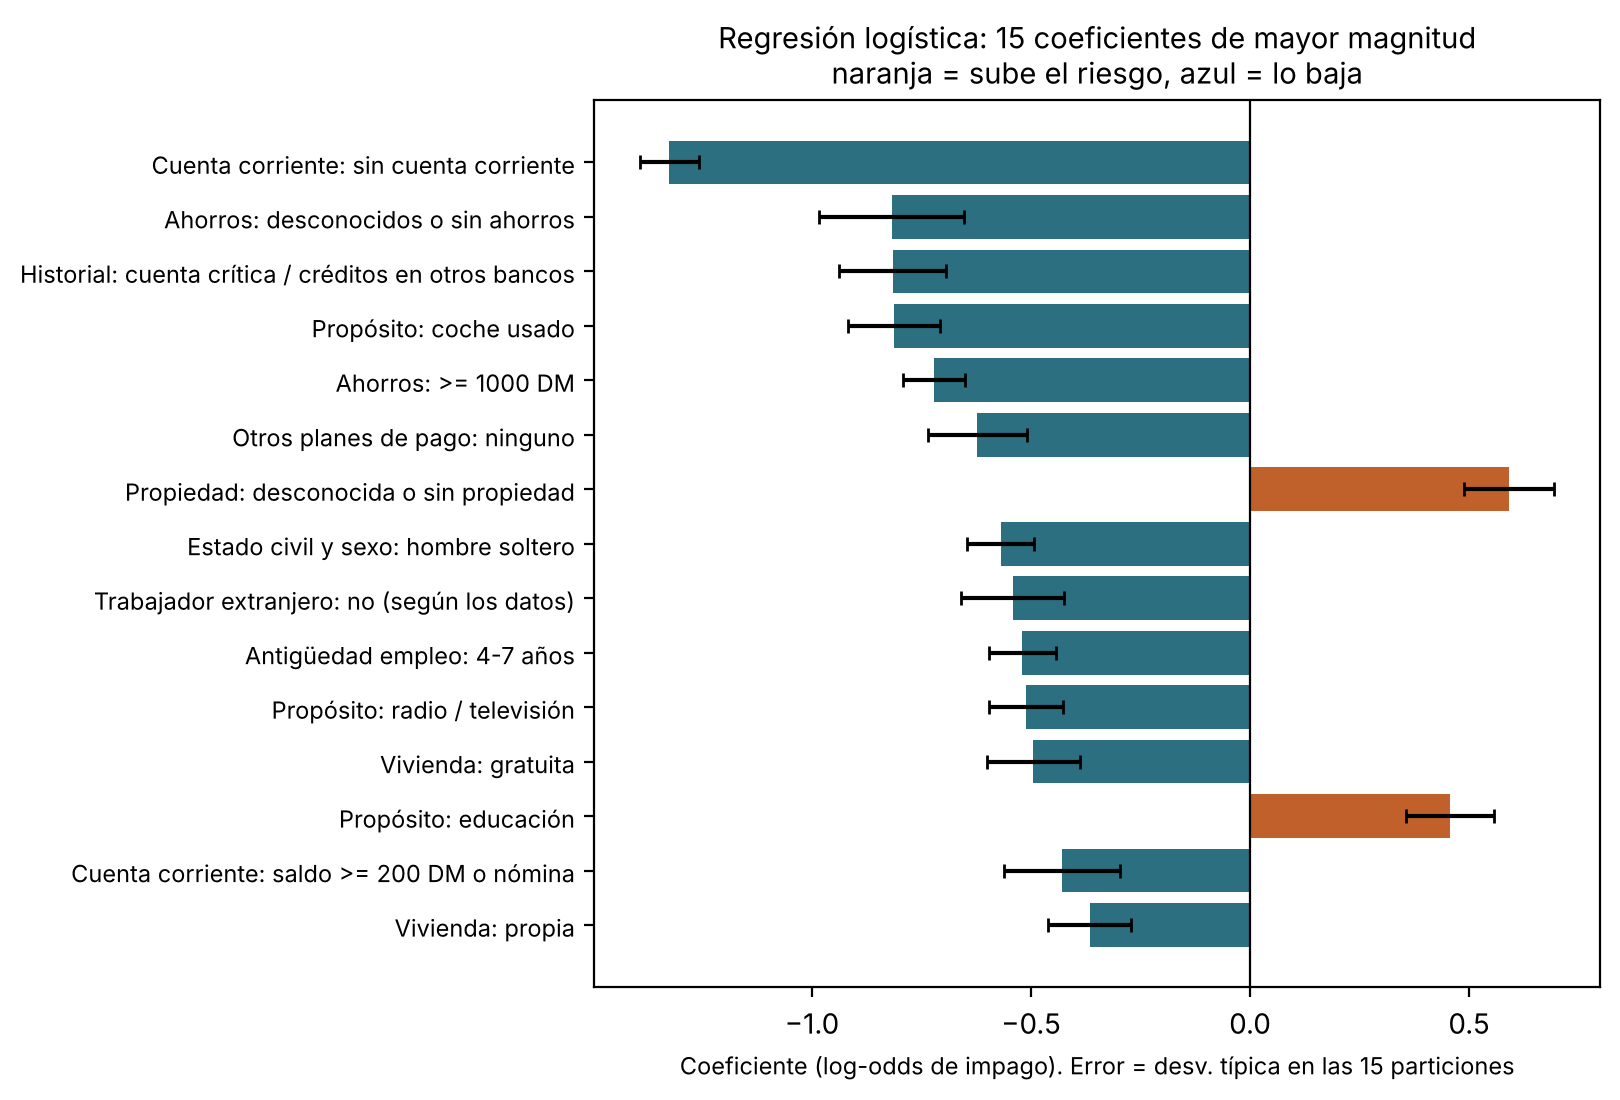

In [10]:
top = tabla_coef.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.2, 5.6))
ax.barh(top["etiqueta"], top["coef"], xerr=top["desv_cv"], capsize=2.5,
        color=["#c0612b" if c > 0 else "#2b6f80" for c in top["coef"]])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel(f"Coeficiente (log-odds de impago). Error = desv. típica en las {len(coefs)} particiones", fontsize=8.5)
ax.set_title("Regresión logística: 15 coeficientes de mayor magnitud\nnaranja = sube el riesgo, azul = lo baja", fontsize=10.5)
ax.tick_params(axis="y", labelsize=8.5)
plt.tight_layout()
plt.savefig(os.path.join(r["graphics"], "A_2_3_logistica_coeficientes.png"), dpi=200)
plt.show()

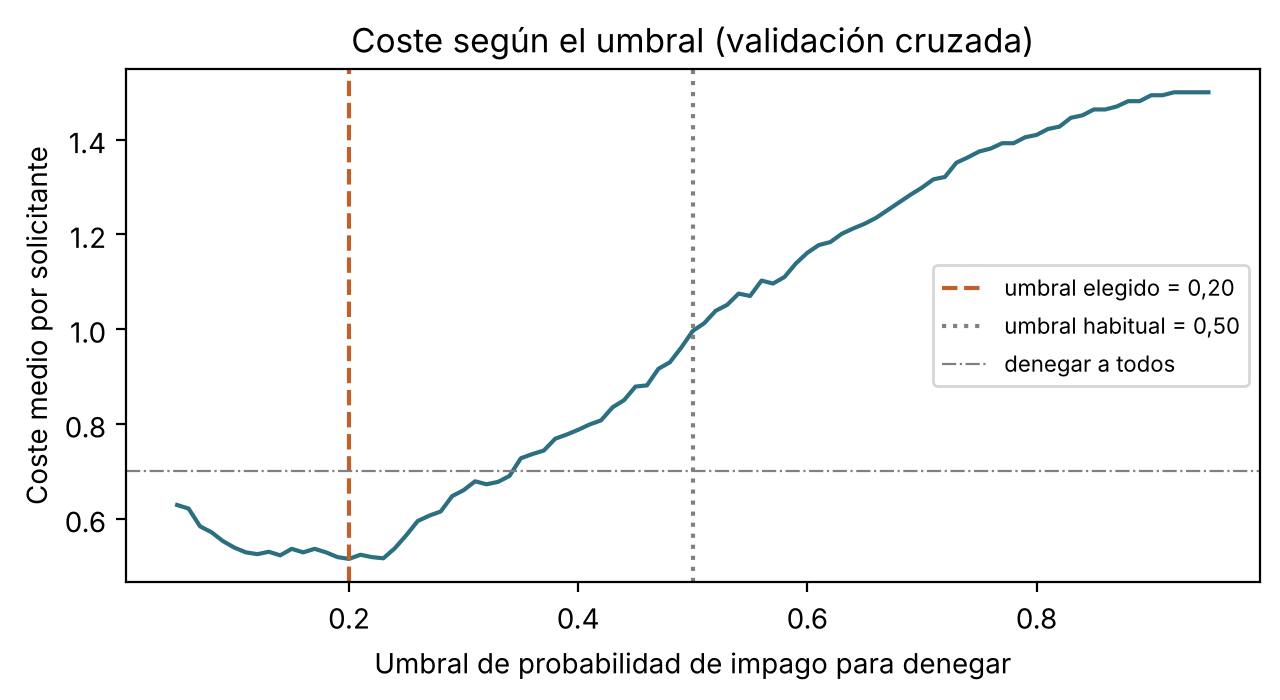

In [11]:
umbrales = np.round(np.arange(0.05, 0.951, 0.01), 2)
costes = [cp.mean_cost(y_train, (oof >= u).astype(int)) for u in umbrales]
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(umbrales, costes, color="#2b6f80")
ax.axvline(umbral, ls="--", color="#c0612b", label=f"umbral elegido = {umbral:.2f}".replace(".", ","))
ax.axvline(0.5, ls=":", color="gray", label="umbral habitual = 0,50")
ax.axhline(coste_denegar, ls="-.", color="gray", lw=0.8, label="denegar a todos")
ax.set_xlabel("Umbral de probabilidad de impago para denegar")
ax.set_ylabel("Coste medio por solicitante")
ax.set_title("Coste según el umbral (validación cruzada)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(r["graphics"], "A_2_3_logistica_coste_umbral.png"), dpi=200)
plt.show()

## 6. Estabilidad

Signo de cada coeficiente en las particiones y coincidencia del top 5 (Jaccard medio entre todos los pares, función común).

In [12]:
top5 = [set(np.argsort(-np.abs(c))[:5]) for c in coefs]
jaccard_top5 = cp.stability(top5)
estables = (tabla_coef["signo_estable_%"] == 100)
print(f"Top 10 con signo estable en todas las particiones: {estables.head(10).sum()} de 10")
print(f"Desv. típica de los 10 principales: {tabla_coef.head(10)['desv_cv'].min():.3f} - {tabla_coef.head(10)['desv_cv'].max():.3f}")
print(f"Coeficientes con signo siempre igual: {estables.sum()} de {len(estables)} ({estables.mean():.0%})")
print(f"Mayor |coef| entre los que cambian de signo: {tabla_coef.loc[~estables, 'coef'].abs().max():.3f}")
print(f"Jaccard medio del top 5: {jaccard_top5:.3f}")

Top 10 con signo estable en todas las particiones: 10 de 10
Desv. típica de los 10 principales: 0.067 - 0.166
Coeficientes con signo siempre igual: 29 de 48 (60%)
Mayor |coef| entre los que cambian de signo: 0.318
Jaccard medio del top 5: 0.623


## 7. Ejemplo a mano

Un solicitante del test con probabilidad cercana a 0,35. La probabilidad se reconstruye sumando las aportaciones y aplicando la sigmoide, y se comprueba que coincide con la del modelo.

In [13]:
Z = modelo.named_steps["prep"].transform(X_test)
i = int(np.argmin(np.abs(p_test - 0.35)))
aportes = pd.DataFrame({"etiqueta": [etiqueta(c) for c in cols], "valor": Z[i], "coef": lr.coef_[0], "aporte": Z[i] * lr.coef_[0]})
aportes = aportes[aportes["valor"] != 0]  # las categorías de referencia no aportan (están en el intercepto)
aportes = aportes.reindex(aportes["aporte"].abs().sort_values(ascending=False).index)
aportes.to_csv(os.path.join(r["results"], "ejemplo_a_mano_A_logistica.csv"), index=False)

z = lr.intercept_[0] + aportes["aporte"].sum()
p = 1 / (1 + np.exp(-z))
ejemplo = {"indice": int(X_test.index[i]), "z": float(z), "p": float(p), "p_modelo": float(p_test[i]),
           "decision": "denegar" if p >= umbral else "conceder", "impago_real": int(y_test.iloc[i]),
           "suma_aportes": float(aportes["aporte"].sum())}
print(X_test.iloc[i].to_string())
print(f"\nz = {lr.intercept_[0]:.3f} + ({aportes['aporte'].sum():.3f}) = {z:.3f}")
print(f"p = 1 / (1 + e^{-z:.3f}) = {p:.3f}   (modelo: {p_test[i]:.3f})")
print(f"Decisión: {ejemplo['decision']}   Realidad: {'impagó' if ejemplo['impago_real'] else 'pagó'}")
aportes.round(3)

checking_status                              no checking
duration                                              12
credit_history            critical/other existing credit
purpose                                        education
credit_amount                                       2748
savings_status                                      <100
employment                                           >=7
installment_commitment                                 2
personal_status                       female div/dep/mar
other_parties                                       none
residence_since                                        4
property_magnitude                     no known property
age                                                   57
other_payment_plans                                 bank
housing                                         for free
existing_credits                                       3
job                                   unskilled resident
num_dependents                 

,etiqueta,valor,coef,aporte
9,Cuenta corriente: sin cuenta corriente,1.000,-1.325,-1.325
11,Historial: cuenta crítica / créditos en otros ...,1.000,-0.816,-0.816
38,Propiedad: desconocida o sin propiedad,1.000,0.592,0.592
41,Vivienda: gratuita,1.000,-0.495,-0.495
16,Propósito: educación,1.000,0.456,0.456
5,Nº de créditos en el banco (por desv. típica),2.809,0.101,0.284
2,Cuota sobre renta (1-4) (por desv. típica),-0.838,0.331,-0.278
0,Duración (por desv. típica),-0.743,0.324,-0.241
30,Antigüedad empleo: >= 7 años,1.000,-0.112,-0.112
4,Edad (por desv. típica),1.964,-0.054,-0.106


## 8. Comprobación de los efectos raros del historial de crédito

Tasa de impago por categoría en todo el dataset (descriptivo, no se usa para entrenar).

In [14]:
X_all, y_all = cp.load_data(FOLDER)
tasas = y_all.groupby(X_all["credit_history"]).agg(["mean", "size"]).rename(columns={"mean": "tasa_impago", "size": "n"})
tasas.sort_values("tasa_impago").round(3)

,tasa_impago,n
credit_history,,
critical/other existing credit,0.171,293
delayed previously,0.318,88
existing paid,0.319,530
all paid,0.571,49
no credits/all paid,0.625,40


## 9. Equidad por edad

Con la función común, en el test (para el apartado 4.2).

In [15]:
eq = cp.equity(y_test, p_test, X_test["age"], umbral)
cp.storage_equity(FOLDER, SUBGRUPO, MODELO, eq)
eq.round(3)

,Tasa de concesión,Buenos denegados,Malos detectados,n
grupo de edad,,,,
>25 años,0.436,0.457,0.875,156.0
≤25 años,0.295,0.583,0.850,44.0
diferencia,0.140,0.126,0.025,NaN


## 10. Auditoría

Respuestas a las 9 preguntas comunes (`AUDIT_LIST`) para la logística.

In [16]:
respuestas = [
    ("Sí", "Suma de aportaciones y sigmoide; ejemplo a mano en el apartado 7."),
    ("Sí", f"{len(cols) + 1} parámetros en una sola tabla."),
    ("Sí", "La explicación son los propios coeficientes; no hay aproximación externa."),
    ("Sí", f"Jaccard medio del top 5 = {jaccard_top5:.2f}; los 10 coeficientes principales mantienen el signo en todas las particiones."),
    ("Sí", "Coeficientes directos de edad, estado civil y sexo y trabajador extranjero."),
    ("Sí", "Predicciones por grupo de edad con la función común (apartado 9)."),
    ("Sí", "Se detectan efectos contraintuitivos en el historial de crédito (apartado 8)."),
    ("Parcial", "Las aportaciones dan los motivos y los odds ratio permiten calcular cambios, pero la logística no genera contrafactuales por sí sola."),
    ("Sí", "Model card completa en la wiki (apartado 4.3)."),
]
cp.storage_auditory(FOLDER, SUBGRUPO, MODELO, respuestas)

,valoración,evidencia
pregunta,,
1. ¿Se puede reproducir una decisión concreta a mano o con una fórmula documentada?,Sí,Suma de aportaciones y sigmoide; ejemplo a man...
"2. ¿Se puede revisar el modelo completo con un número manejable de elementos (coeficientes, reglas, nodos)?",Sí,49 parámetros en una sola tabla.
3. ¿La explicación sale del propio modelo o de una aproximación externa?,Sí,La explicación son los propios coeficientes; n...
4. ¿La explicación es estable entre ejecuciones o particiones (Jaccard del top-5)?,Sí,Jaccard medio del top 5 = 0.62; los 10 coefici...
"5. ¿Se puede ver qué peso tienen las variables sensibles o sus aproximaciones (edad, estado civil)?",Sí,"Coeficientes directos de edad, estado civil y ..."
6. ¿Se puede comprobar la equidad por grupos de edad?,Sí,Predicciones por grupo de edad con la función ...
7. ¿Se puede detectar un comportamiento ilógico del modelo (efectos contraintuitivos)?,Sí,Se detectan efectos contraintuitivos en el his...
8. ¿Puede el solicitante recibir una explicación útil y accionable (qué tendría que cambiar)?,Parcial,Las aportaciones dan los motivos y los odds ra...
9. ¿Está documentado con una model card completa?,Sí,Model card completa en la wiki (apartado 4.3).


## 11. Archivos para el resto del grupo

In [17]:
pd.DataFrame({"index": X_test.index, "bad": y_test.values, "prob_bad": p_test,
              "decision": np.where(p_test >= umbral, "denegar", "conceder")}).to_csv(
    os.path.join(r["results"], "predicciones_A_logistica.csv"), index=False)

resumen = {
    "C": C, "auc_por_C": auc_por_C.to_dict(), "umbral": umbral, "umbral_teorico": cp.THE_THRES,
    "cv": {k: [float(tabla_cv[k].mean()), float(tabla_cv[k].std())] for k in tabla_cv.columns},
    "comparacion_umbrales": comparacion.to_dict(orient="index"),
    "coste_aprobar_todos": coste_aprobar, "coste_denegar_todos": coste_denegar,
    "test": res_test, "test_ic95": {k: list(map(float, v)) for k, v in ic.items()},
    "test_tasa_denegacion": float(pred.mean()), "test_brier": float(brier_score_loss(y_test, p_test)),
    "test_confusion": {"VP": int(((pred==1)&(yt==1)).sum()), "FN": int(((pred==0)&(yt==1)).sum()),
                       "FP": int(((pred==1)&(yt==0)).sum()), "VN": int(((pred==0)&(yt==0)).sum())},
    "intercepto": float(lr.intercept_[0]), "n_parametros": len(cols) + 1, "n_particiones": len(coefs),
    "jaccard_top5": jaccard_top5, "coefs_signo_estable": int(estables.sum()), "n_coefs": len(estables),
    "max_coef_inestable": float(tabla_coef.loc[~estables, "coef"].abs().max()),
    "desv_top10": [float(tabla_coef.head(10)["desv_cv"].min()), float(tabla_coef.head(10)["desv_cv"].max())],
    "escalado": {v: [float(escala.mean_[k]), float(escala.scale_[k])] for k, v in enumerate(num)},
    "efectos_numericos": efectos.to_dict(orient="records"),
    "ejemplo": ejemplo, "ejemplo_datos": {k: (v.item() if hasattr(v, "item") else v) for k, v in X_test.iloc[i].to_dict().items()},
    "tasas_historial": tasas["tasa_impago"].to_dict(),
}
with open(os.path.join(r["results"], "resumen_A_logistica.json"), "w", encoding="utf-8") as f:
    json.dump(resumen, f, indent=2, ensure_ascii=False, default=float)
sorted(os.listdir(r["results"])), sorted(os.listdir(r["graphics"]))

(['auditoria_A_logistica.csv',
  'coeficientes_A_logistica.csv',
  'ejemplo_a_mano_A_logistica.csv',
  'equidad_A_logistica.csv',
  'predicciones_A_logistica.csv',
  'resultados_A_logistica.csv',
  'resumen_A_logistica.json'],
 ['A_2_3_logistica_coeficientes.png', 'A_2_3_logistica_coste_umbral.png'])